# 01 — Assess the data before modelling

**Question:** Which measurements and temporal behaviours must an expected-behaviour model accommodate?

We use the **2020 UCI MetroPT-3** compressor recording: seven analogue and eight digital channels from one train APU. This is different from the larger 2022 MetroPT release. All 15 signals are assessed; no detector or automatic feature selection is fitted here.

**Boundaries fixed before value exploration:** February is the reference period; March–May supports development. From **1 June onward**, only timestamps, source indices and missing-cell counts are exposed. The final sensor values are unavailable to this notebook. The observed recording extends four hours into 1 September; the declared audit window includes that tail. A report-free period is not proven healthy.

**Reusability:** the loader, sensor dictionary, valve interpretation and incident records belong to `metropt.py`. The time, distribution, run-duration and relationship calculations in `assessment.py` accept explicit inputs and contain no equipment-specific names. A wide table preserves aligned sensors without creating millions of unnecessary long-format rows.

Sources: [UCI dataset and licence](https://doi.org/10.24432/C5VW3R), the supplied `Data Description_Metro.pdf`, and [leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage). Unknown timezone, pulse encoding and maintenance-record inconsistencies remain explicit.

In [1]:
from dataclasses import asdict
from importlib.metadata import version
from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from ts_anomaly.metropt import METRICS, fetch_metropt, read_metropt, operating_state, incident_records
from ts_anomaly.assessment import (
    split_development, sampling_report, bin_coverage, duplicate_report, signal_profile,
    state_runs, aggregate_gauges, segment_acf, relationship_report,
)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "configs/metropt.json").is_file(), "Open the repository root or notebooks directory."
config = json.loads((ROOT / "configs/metropt.json").read_text())
OUTPUT = ROOT / "outputs/metropt_assessment"
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 95, "axes.grid": True, "grid.alpha": 0.2})
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)

## 1. Load a verified source and protect the test period

The first run downloads about 218 MB into ignored `data/metropt/`. SHA-256 hashes identify the exact CSV and dictionary; later runs verify the cache. Source readings are neither interpolated nor clipped. The exported row index is retained only for the structural audit, never as a feature. Timestamps remain timezone-unspecified recorded time.

In [2]:
source_path = fetch_metropt(config["source"], ROOT / "data/metropt")
data, timeline = read_metropt(source_path, before=config["test_start"])
training, validation = split_development(data, config["start"], config["train_end"], config["test_start"])
assert data.timestamp.lt(pd.Timestamp(config["test_start"])).all()
assert not set(METRICS).intersection(timeline.columns)

periods = pd.DataFrame([
    ("reference", config["start"], config["train_end"], "value exploration"),
    ("development", config["train_end"], config["test_start"], "value exploration"),
    ("reserved test", config["test_start"], config["end"], "availability only"),
], columns=["period", "start_inclusive", "end_exclusive", "permitted_use"])
periods["rows"] = [len(training), len(validation), int(timeline.timestamp.ge(config["test_start"]).sum())]
display(periods)
print(f"Source: {len(timeline):,} rows; development values: {len(data):,} rows.")
print("Source-index duplicates:", timeline.source_index.duplicated().sum())
print("Timezone:", config["timezone"], "(unknown; no UTC conversion)")

,period,start_inclusive,end_exclusive,permitted_use,rows
0,reference,2020-02-01 00:00:00,2020-03-01 00:00:00,value exploration,214850
1,development,2020-03-01 00:00:00,2020-06-01 00:00:00,value exploration,641982
2,reserved test,2020-06-01 00:00:00,2020-09-01 04:00:00,availability only,660116


Source: 1,516,948 rows; development values: 856,832 rows.
Source-index duplicates: 0
Timezone: None (unknown; no UTC conversion)


In [3]:
dictionary = pd.DataFrame({name: asdict(definition) for name, definition in METRICS.items()}).T
analog = dictionary.index[dictionary.kind.eq("gauge")].tolist()
digital = dictionary.index[~dictionary.kind.eq("gauge")].tolist()
display(dictionary[["description", "unit", "kind", "role"]])
display(dictionary.loc[dictionary.note.ne(""), ["note"]])
dictionary.to_csv(OUTPUT / "measurement_dictionary.csv", index_label="measurement")

,description,unit,kind,role
TP2,Compressor pressure,bar,gauge,measurement
TP3,Pneumatic-panel pressure,bar,gauge,measurement
H1,Separator-related pressure,bar,gauge,measurement
DV_pressure,Dryer pressure drop,bar,gauge,measurement
Reservoirs,Reservoir pressure,bar,gauge,measurement
Oil_temperature,Compressor oil temperature,degC,gauge,measurement
Motor_current,One motor phase current,A,gauge,measurement
COMP,Intake-valve control,None,state,context
DV_eletric,Outlet-valve control,None,state,context
Towers,Drying-tower selection,None,state,context


,note
DV_pressure,Source associates near-zero readings with loading; verify empirically.
Motor_current,Approximate operating levels in the source are not hard limits.
COMP,Active means no air intake: off or unloaded.
DV_eletric,Source: active during loading. CSV spelling retained.
MPG,Source says behaviour follows COMP; compare rather than assume equivalence.
LPS,Source describes activation below 7 bar; not independent ground truth.
Oil_level,Source says active means low oil; encoding/polarity requires confirmation.
Caudal_impulses,Pulse encoding and volume per pulse are unspecified; do not sum or difference as a counter.


**Reading the dictionary.** A measurement kind describes its representation, not its probability distribution. The expected 0/1 encoding of state signals is checked below. `Caudal_impulses` remains a pulse signal with unresolved encoding; we do not infer a flow rate or cumulative counter. Slightly negative pressure values are retained because the source provides no calibrated sensor-validity limits.

The supplied PDF describes 15,169,480 points at 1 Hz, whereas UCI describes 1,516,948 exported records and also mentions 0.1 Hz. We use the actual file and timestamps, not either rate as an exact time grid. No timezone is established by these documents.

## 2. Is the recording complete and ordered?

First audit the full timeline, without examining reserved sensor values. A **collection gap** here is an interval greater than 15 seconds: a declared continuity rule accommodating the observed approximately 10-second sampling. It does not identify equipment downtime. Minute-bin occupancy assumes continuous collection over the declared period; it is not an estimate of missing samples.

In [4]:
sampling, interval_counts, gaps = sampling_report(timeline, config["gap_threshold"])
display(sampling.drop(columns="entity_id").T.rename(columns={0: "full recording"}))
display(interval_counts.nlargest(8, "count")[["interval_s", "count"]])
display(gaps.nlargest(5, "elapsed_s")[["previous_time", "next_time", "elapsed_s"]])
print("Missing measurement cells in the full source:", int(timeline.missing_measurements.sum()))

conflicts = duplicate_report(data, list(METRICS))
print("Duplicate development timestamp groups:", len(conflicts))
assert conflicts.empty, "Resolve duplicate records before calculating temporal diagnostics."
assert data.timestamp.is_monotonic_increasing
sampling.to_csv(OUTPUT / "sampling_summary.csv", index=False)
gaps.to_csv(OUTPUT / "collection_gaps.csv", index=False)

,full recording
rows,1516948
unique_times,1516948
start,2020-02-01 00:00:00
end,2020-09-01 03:59:50
duplicate_rows,0
backward_steps,0
median_interval_s,10.0
p95_interval_s,10.0
max_interval_s,172918.0
gaps,363


,interval_s,count
0,10.0,1337521
1,9.0,128277
2,12.0,38321
3,13.0,7988
4,11.0,4471
5,21.0,10
6,19.0,5
7,22.0,4


,previous_time,next_time,elapsed_s
133,2020-04-25 01:10:51,2020-04-27 01:12:49,172918.0
238,2020-06-27 10:53:07,2020-06-28 23:07:43,130476.0
35,2020-02-28 23:57:08,2020-03-01 04:00:09,100981.0
318,2020-08-04 07:42:28,2020-08-05 08:23:01,88833.0
186,2020-05-24 00:39:23,2020-05-25 01:14:14,88491.0


Missing measurement cells in the full source: 0
Duplicate development timestamp groups: 0


,period,expected_minutes,occupied_minutes,occupancy
0,reference,41760,35525,0.8507
1,development,132480,107032,0.8079
2,reserved test,132720,110163,0.8300


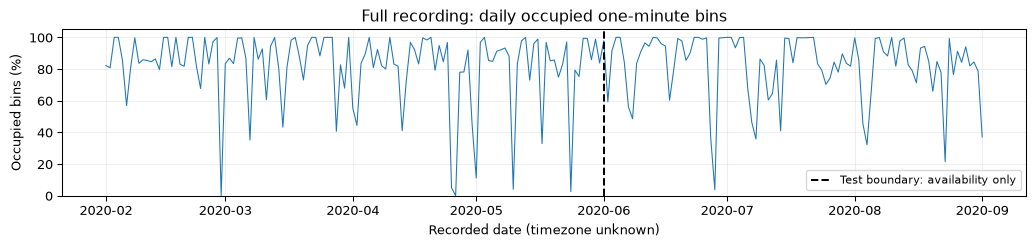

In [5]:
coverage = bin_coverage(timeline.timestamp, config["start"], config["end"])
coverage_rows = []
for period in periods.itertuples():
    selected = coverage.loc[(coverage.index >= period.start_inclusive) & (coverage.index < period.end_exclusive)]
    coverage_rows.append({"period": period.period, "expected_minutes": len(selected),
                          "occupied_minutes": int(selected.occupied.sum()),
                          "occupancy": selected.occupied.mean()})
coverage_summary = pd.DataFrame(coverage_rows)
display(coverage_summary.round(4))

daily_coverage = coverage.occupied.resample("1D").mean()
fig, ax = plt.subplots(figsize=(11, 2.7))
ax.plot(daily_coverage.index, 100 * daily_coverage, linewidth=0.8)
ax.axvline(pd.Timestamp(config["test_start"]), color="black", linestyle="--", label="Test boundary: availability only")
ax.set(title="Full recording: daily occupied one-minute bins", ylabel="Occupied bins (%)", xlabel="Recorded date (timezone unknown)", ylim=(0, 105))
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
coverage_summary.to_csv(OUTPUT / "coverage_summary.csv", index=False)

In [6]:
display(Markdown(
    f"**Finding:** the reference period has **{coverage_summary.occupancy.iloc[0]:.1%} minute-bin occupancy** "
    f"despite **{int(timeline.missing_measurements.sum())} missing cells** in the full file. "
    f"The longest observed inter-record interval is **{gaps.elapsed_s.max() / 3600:.1f} hours**. "
    "Missing rows must interrupt temporal calculations; a zero-cell-missingness report alone would be misleading. "
    "The final plotted day contains only the declared four-hour tail. Occupancy does not establish uptime or the reason for collection gaps."
))

**Finding:** the reference period has **85.1% minute-bin occupancy** despite **0 missing cells** in the full file. The longest observed inter-record interval is **48.0 hours**. Missing rows must interrupt temporal calculations; a zero-cell-missingness report alone would be misleading. The final plotted day contains only the declared four-hour tail. Occupancy does not establish uptime or the reason for collection gaps.

## 3. What does each signal look like?

All value diagnostics below use February or March–May only. Continuous summaries describe finite observed readings, without normality assumptions. Digital value frequencies are sample proportions, not elapsed-time proportions. Extreme finite readings remain in the analysis; the supplied metadata do not establish hard physical rejection bounds.

In [7]:
training_profile = signal_profile(training, METRICS).set_index("measurement")
validation_profile = signal_profile(validation, METRICS).set_index("measurement")
display(training_profile[["kind", "missing", "nonfinite", "unexpected_encoding", "unique"]])
display(training_profile.loc[analog, ["min", "p01", "median", "p99", "max", "sd"]].round(4))
print("Unexpected state encodings in development:", int(validation_profile.unexpected_encoding.sum()))
training_profile.to_csv(OUTPUT / "reference_signal_profile.csv")
validation_profile.to_csv(OUTPUT / "development_signal_profile.csv")

,kind,missing,nonfinite,unexpected_encoding,unique
measurement,,,,,
TP2,gauge,0,0,0,2357
TP3,gauge,0,0,0,1182
H1,gauge,0,0,0,1275
DV_pressure,gauge,0,0,0,242
Reservoirs,gauge,0,0,0,1180
Oil_temperature,gauge,0,0,0,1130
Motor_current,gauge,0,0,0,1083
COMP,state,0,0,0,2
DV_eletric,state,0,0,0,2


,min,p01,median,p99,max,sd
measurement,,,,,,
TP2,-0.030,-0.0220,-0.0120,10.1280,10.5440,2.1977
TP3,7.324,8.0660,8.9360,10.0500,10.1640,0.5521
H1,-0.030,-0.0220,8.8560,10.0240,10.1580,2.1992
DV_pressure,-0.028,-0.0240,-0.0180,-0.0120,6.5300,0.1048
Reservoirs,7.326,8.0680,8.9380,10.0500,10.1680,0.5515
Oil_temperature,31.975,47.4250,56.6250,64.1750,69.1500,3.4132
Motor_current,0.020,0.0325,0.0375,6.1675,8.2925,1.9621


Unexpected state encodings in development: 0


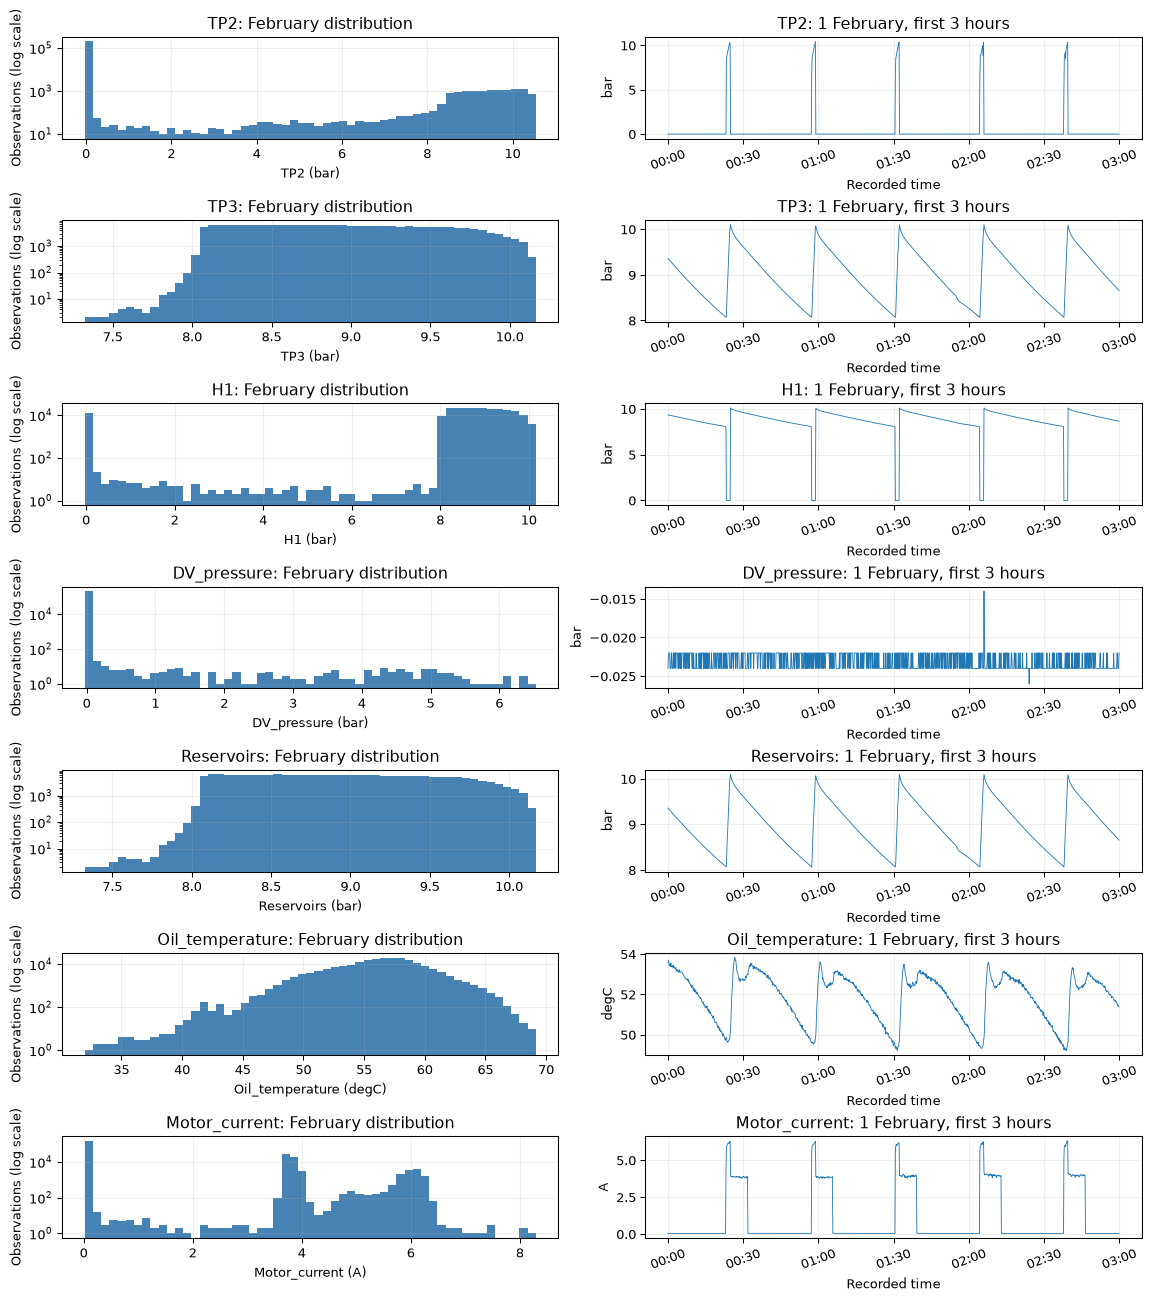

In [8]:
# First three recorded hours: the same window for every sensor, chosen without labels.
example_end = training.timestamp.min() + pd.Timedelta(hours=3)
example = training.loc[training.timestamp.lt(example_end)]
fig, axes = plt.subplots(7, 2, figsize=(12, 13.5), layout="constrained")
for row, name in enumerate(analog):
    unit = METRICS[name].unit
    axes[row, 0].hist(training[name], bins=55, color="steelblue", edgecolor="none", log=True)
    axes[row, 0].set(title=f"{name}: February distribution", xlabel=f"{name} ({unit})", ylabel="Observations (log scale)")
    axes[row, 1].plot(example.timestamp, example[name], linewidth=0.65)
    axes[row, 1].set(title=f"{name}: 1 February, first 3 hours", xlabel="Recorded time", ylabel=unit)
    axes[row, 1].xaxis.set_major_locator(mdates.MinuteLocator(byminute=[0, 30]))
    axes[row, 1].xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    axes[row, 1].tick_params(axis="x", labelrotation=20)
plt.show()

In [9]:
frequency_rows = []
run_summaries = []
for period_name, frame in [("reference", training), ("development", validation)]:
    elapsed = frame.timestamp.diff().dt.total_seconds()
    connected_hours = elapsed.where(elapsed.le(pd.Timedelta(config["gap_threshold"]).total_seconds()), 0).sum() / 3600
    for name in digital:
        for value, count in frame[name].value_counts(dropna=False).items():
            frequency_rows.append({"period": period_name, "measurement": name, "value": value,
                                   "observations": count, "fraction": count / len(frame)})
        runs = state_runs(frame.set_index("timestamp")[name], config["gap_threshold"])
        complete = runs.loc[~runs.left_censored & ~runs.right_censored]
        run_summaries.append({"period": period_name, "measurement": name, "runs": len(runs),
                             "observed_transitions": int((~runs.left_censored).sum()),
                             "transitions_per_connected_hour": (~runs.left_censored).sum() / connected_hours,
                             "complete_runs": len(complete),
                             "median_complete_span_s": complete.observed_span_s.median(),
                             "longest_observed_span_hours": runs.observed_span_s.max() / 3600})
frequencies = pd.DataFrame(frequency_rows)
run_summary = pd.DataFrame(run_summaries)
display(frequencies.pivot(index=["measurement", "value"], columns="period",
                          values=["observations", "fraction"]).fillna(0).round(6))
display(run_summary.loc[run_summary.period.eq("reference")].drop(columns="period").round(3))
frequencies.to_csv(OUTPUT / "digital_value_frequencies.csv", index=False)
run_summary.to_csv(OUTPUT / "digital_runs.csv", index=False)

observations              fraction          
period                 development reference development reference
measurement     value                                             
COMP            0.0       110831.0   13031.0    0.172639  0.060652
                1.0       531151.0  201819.0    0.827361  0.939348
Caudal_impulses 0.0        88415.0       0.0    0.137722  0.000000
                1.0       553567.0  214850.0    0.862278  1.000000
DV_eletric      0.0       530871.0  201817.0    0.826925  0.939339
                1.0       111111.0   13033.0    0.173075  0.060661
LPS             0.0       640301.0  214849.0    0.997382  0.999995
                1.0         1681.0       1.0    0.002618  0.000005
MPG             0.0       115836.0   13031.0    0.180435  0.060652
                1.0       526146.0  201819.0    0.819565  0.939348
Oil_level       0.0        10537.0       0.0    0.016413  0.000000
                1.0       631445.0  214850.0    0.983587  1.000000
Pressure_switch 0.0         6186.0     163.0    0.009636  0.000759
                1.0       635796.0  214687.0    0.990364  0.999241
Towers          0.0        57919.0    6502.0    0.090219  0.030263
                1.0       584063.0  208348.0    0.909781  0.969737

,measurement,runs,observed_transitions,transitions_per_connected_hour,complete_runs,median_complete_span_s,longest_observed_span_hours
0,COMP,2358,2322,3.926,2295,148.0,0.757
1,DV_eletric,2358,2322,3.926,2295,148.0,0.757
2,Towers,3155,3119,5.273,3093,50.0,0.774
3,MPG,2358,2322,3.926,2295,148.0,0.757
4,LPS,37,1,0.002,0,NaN,67.984
5,Pressure_switch,360,324,0.548,302,0.0,20.029
6,Oil_level,36,0,0.000,0,NaN,67.984
7,Caudal_impulses,36,0,0.000,0,NaN,67.984


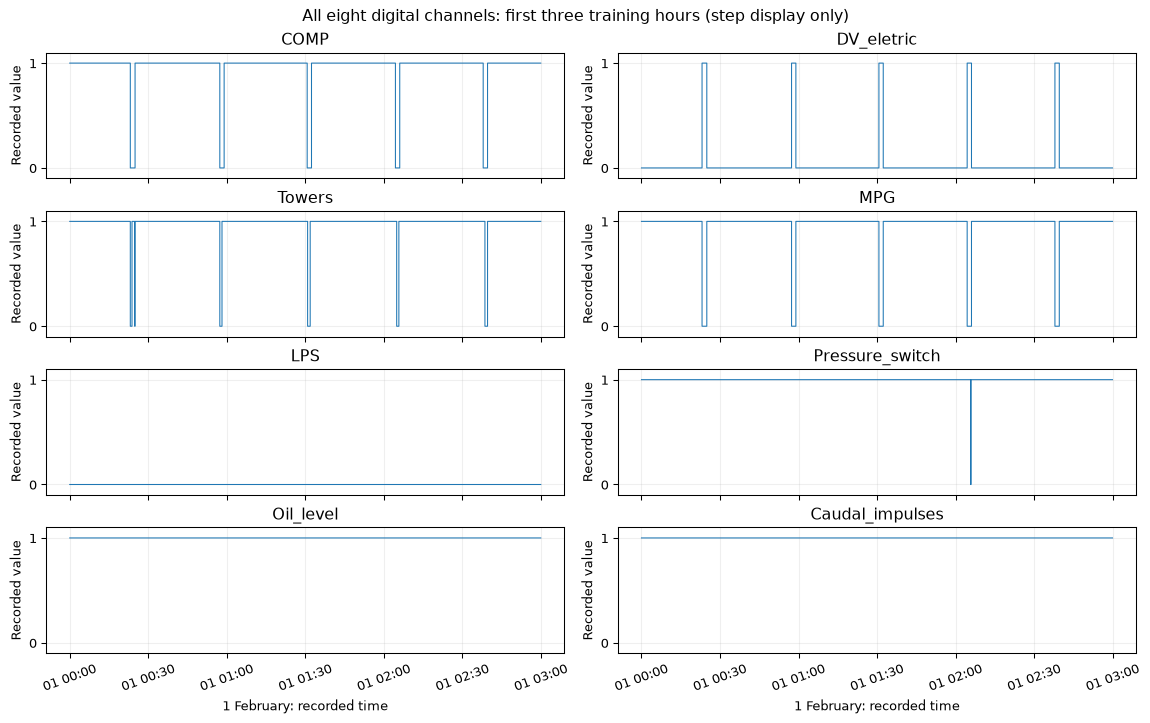

**Finding:** Oil_level, Caudal_impulses are constant in February. Oil_level, Caudal_impulses vary in March–May. Constant training data cannot estimate their alternative-state behaviour. These channels remain in the inventory, with an unresolved modelling role. Pulse levels are not volume measurements. The run table breaks at gaps and counts only observable transitions. Run-duration bounds assume no hidden switches between samples; censored runs are excluded from the complete-run median. Zero-duration spans can be single-sample pulses, not instantaneous physical events.

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(12, 7.5), sharex=True, layout="constrained")
for ax, name in zip(axes.flat, digital):
    ax.step(example.timestamp, example[name], where="post", linewidth=0.8)
    ax.set(title=name, ylabel="Recorded value", ylim=(-0.1, 1.1))
    ax.set_yticks([0, 1])
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[-1]:
    ax.set_xlabel("1 February: recorded time")
fig.suptitle("All eight digital channels: first three training hours (step display only)")
plt.show()

constant = training_profile.index[training_profile.unique.eq(1)].tolist()
changed = [name for name in constant if validation_profile.loc[name, "unique"] > 1]
display(Markdown(
    f"**Finding:** {', '.join(constant) or 'no signals'} are constant in February. "
    f"{', '.join(changed) or 'None'} vary in March–May. Constant training data cannot estimate their alternative-state behaviour. "
    "These channels remain in the inventory, with an unresolved modelling role. Pulse levels are not volume measurements. "
    "The run table breaks at gaps and counts only observable transitions. Run-duration bounds assume no hidden switches between samples; censored runs are excluded from the complete-run median. Zero-duration spans can be single-sample pulses, not instantaneous physical events."
))

## 4. Temporal dependence and changes over development

The native timestamps are irregular. For **continuous-signal diagnostics only**, form one-minute observation means and require at least five finite readings per sensor per minute. Empty or under-supported bins stay missing. These means are not time-weighted integrals and can hide brief events; native distributions and digital transitions remain available above. A mean labelled at minute start becomes available only at minute end.

For autocorrelation, select the longest uninterrupted valid reference segment for each signal. Use the conventional demeaned ACF, $r_k=\sum_{t=k+1}^n(x_t-\bar x)(x_{t-k}-\bar x)/\sum_{t=1}^n(x_t-\bar x)^2$. Limit the maximum lag to one quarter of that segment. These are descriptive correlations, without IID significance bands or a stationarity claim. [Statsmodels ACF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.acf.html).

In [11]:
minute_training, minute_counts = aggregate_gauges(
    training, analog, config["diagnostic_frequency"], config["minimum_samples_per_bin"])
minute_development, development_counts = aggregate_gauges(
    data, analog, config["diagnostic_frequency"], config["minimum_samples_per_bin"])
support = pd.DataFrame({"usable_minutes": minute_training.notna().sum(),
                        "bins_in_reference_file_span": len(minute_training)})
support["usable_fraction"] = support.usable_minutes / support.bins_in_reference_file_span
# This denominator is the observed reference file span, unlike declared-window coverage above.
display(support.round(4))

curves, segment_rows = {}, []
for name in analog:
    curve, info = segment_acf(minute_training[name], config["diagnostic_frequency"], int(pd.Timedelta(minutes=config["maximum_acf_lag_minutes"]) / pd.Timedelta(config["diagnostic_frequency"])))
    curves[name] = curve
    segment_rows.append({"measurement": name, **info,
                         "max_lag_minutes": curve.lag_minutes.max(), "acf_1minute": curve.acf.iloc[1]})
segments = pd.DataFrame(segment_rows)
display(segments.round(4))
segments.to_csv(OUTPUT / "acf_segments.csv", index=False)

,usable_minutes,bins_in_reference_file_span,usable_fraction
TP2,35475,40318,0.8799
TP3,35475,40318,0.8799
H1,35475,40318,0.8799
DV_pressure,35475,40318,0.8799
Reservoirs,35475,40318,0.8799
Oil_temperature,35475,40318,0.8799
Motor_current,35475,40318,0.8799


,measurement,start,end,samples,max_lag_minutes,acf_1minute
0,TP2,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.4987
1,TP3,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.8981
2,H1,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.5343
3,DV_pressure,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.0051
4,Reservoirs,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.8982
5,Oil_temperature,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.9794
6,Motor_current,2020-02-20 04:35:00,2020-02-23 00:33:00,4079,1019.0,0.8350


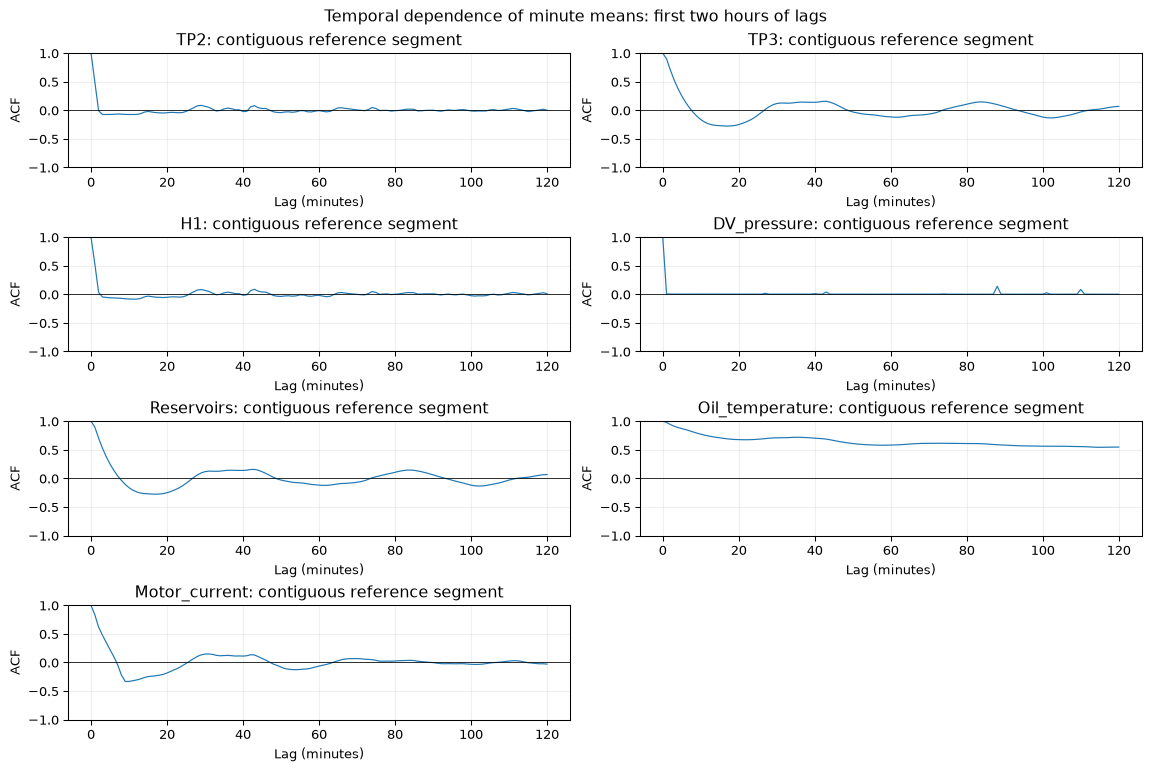

**Finding:** the selected segment contains 4,079–4,079 minute bins. Its maximum reported lag is 1019 minutes. The one-minute ACF values differ across measurements; one temporal model is not automatically appropriate for every signal. Aggregation itself affects short-lag dependence. This segment does not establish stable daily or weekly seasonality.

In [12]:
fig, axes = plt.subplots(4, 2, figsize=(12, 8), layout="constrained")
for ax, name in zip(axes.flat, analog):
    curve = curves[name]
    short = curve.loc[curve.lag_minutes.le(120)]
    ax.plot(short.lag_minutes, short.acf, linewidth=0.9)
    ax.axhline(0, color="black", linewidth=0.6)
    ax.set(title=f"{name}: contiguous reference segment", xlabel="Lag (minutes)", ylabel="ACF", ylim=(-1, 1))
axes.flat[-1].set_visible(False)
fig.suptitle("Temporal dependence of minute means: first two hours of lags")
plt.show()
display(Markdown(
    f"**Finding:** the selected segment contains {segments.samples.min():,}–{segments.samples.max():,} minute bins. "
    f"Its maximum reported lag is {segments.max_lag_minutes.max():.0f} minutes. "
    "The one-minute ACF values differ across measurements; one temporal model is not automatically appropriate for every signal. "
    "Aggregation itself affects short-lag dependence. This segment does not establish stable daily or weekly seasonality."
))

In [13]:
# Check whether the minute-support choice materially changes lag-one diagnostics.
sensitivity_rows = []
for minimum in (4, 5, 6):
    aggregated, _ = aggregate_gauges(training, ["TP3", "Oil_temperature"], "1min", minimum)
    for name in aggregated:
        curve, info = segment_acf(aggregated[name], "1min", 60)
        sensitivity_rows.append({"minimum_samples": minimum, "measurement": name,
                                 "usable_minutes": int(aggregated[name].notna().sum()),
                                 "segment_minutes": info["samples"],
                                 "acf_1minute": curve.acf.iloc[1] if len(curve) > 1 else np.nan})
sensitivity = pd.DataFrame(sensitivity_rows)
display(sensitivity.round(4))
print("The segment may change with support requirements; this is a diagnostic sensitivity check, not threshold tuning.")
sensitivity.to_csv(OUTPUT / "aggregation_sensitivity.csv", index=False)

,minimum_samples,measurement,usable_minutes,segment_minutes,acf_1minute
0,4,TP3,35492,4079,0.8981
1,4,Oil_temperature,35492,4079,0.9794
2,5,TP3,35475,4079,0.8981
3,5,Oil_temperature,35475,4079,0.9794
4,6,TP3,35466,4078,0.8981
5,6,Oil_temperature,35466,4078,0.9794


The segment may change with support requirements; this is a diagnostic sensitivity check, not threshold tuning.


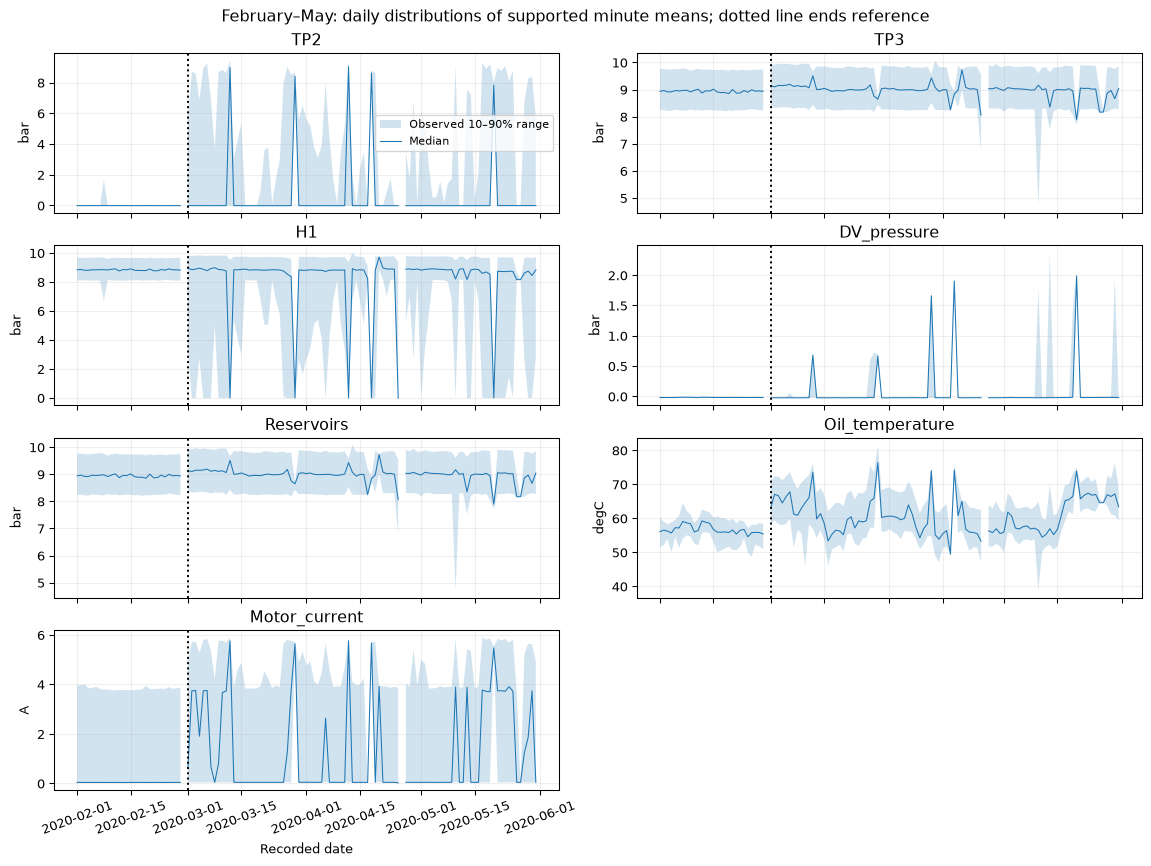

,supported minutes per development day
count,121.0
mean,1174.7
std,336.5
min,0.0
25%,1161.0
50%,1232.0
75%,1412.0
max,1440.0


Bands describe within-day variability, not confidence intervals. Low-coverage days are less representative.


**Finding:** the intake-open sample fraction changes from 6.1% in February to 17.3% in March–May. The oil-temperature median changes from 56.62 to 60.90 degC. These distribution shifts require investigation in Notebook 02; they are not automatically faults or proof of a temperature trend. The periods differ in operating-state mix and coverage, and development contains reported incidents.

In [14]:
daily = minute_development.resample("1D").agg(["count", "median", lambda x: x.quantile(.1), lambda x: x.quantile(.9)])
daily.columns = pd.MultiIndex.from_product([analog, ["minutes", "median", "p10", "p90"]])
fig, axes = plt.subplots(4, 2, figsize=(12, 9), sharex=True, layout="constrained")
for ax, name in zip(axes.flat, analog):
    values = daily[name]
    ax.fill_between(values.index, values.p10, values.p90, alpha=.2, label="Observed 10–90% range")
    ax.plot(values.index, values["median"], linewidth=.8, label="Median")
    ax.axvline(pd.Timestamp(config["train_end"]), color="black", linestyle=":")
    ax.set(title=name, ylabel=METRICS[name].unit)
    ax.tick_params(axis="x", labelrotation=20)
axes.flat[-1].set_visible(False)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Recorded date")
fig.suptitle("February–May: daily distributions of supported minute means; dotted line ends reference")
plt.show()
daily_support = minute_development.notna().all(axis=1).resample("1D").sum()
display(daily_support.describe().rename("supported minutes per development day").to_frame().round(1))
print("Bands describe within-day variability, not confidence intervals. Low-coverage days are less representative.")
daily.to_csv(OUTPUT / "daily_signal_summary.csv")
load_reference = training.COMP.eq(0).mean()
load_development = validation.COMP.eq(0).mean()
display(Markdown(
    f"**Finding:** the intake-open sample fraction changes from {load_reference:.1%} in February to {load_development:.1%} in March–May. "
    f"The oil-temperature median changes from {training.Oil_temperature.median():.2f} to {validation.Oil_temperature.median():.2f} degC. "
    "These distribution shifts require investigation in Notebook 02; they are not automatically faults or proof of a temperature trend. "
    "The periods differ in operating-state mix and coverage, and development contains reported incidents."
))

**Potential periodicity.** A repeating control cycle is different from calendar seasonality. The next summaries compare recorded hours across reference days. At least 30 supported minutes are required per hour. The interquartile band describes variation between days, not independent-sample uncertainty. Unknown timezone and changing operating duty prevent a causal interpretation of time-of-day patterns.

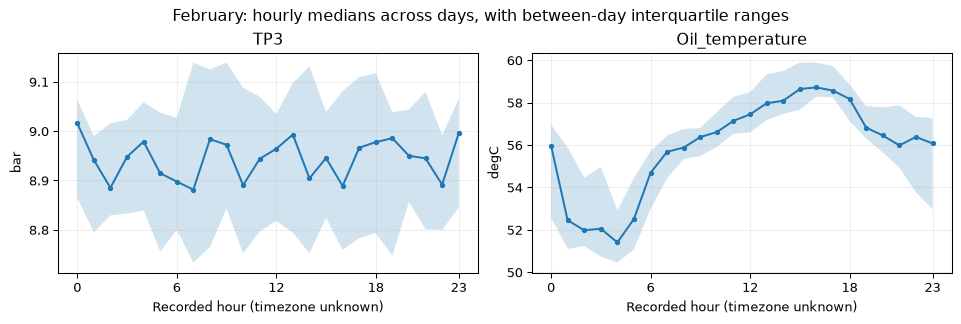

Oil_temperature         Motor_current       
                    count  median         count median
timestamp                                             
Friday                  4  56.955             4  0.038
Monday                  4  55.961             4  0.038
Saturday                4  56.598             4  0.038
Sunday                  4  56.635             4  0.038
Thursday                4  56.874             4  0.038
Tuesday                 4  55.895             4  0.039
Wednesday               4  56.552             4  0.038

Weekday summaries require at least 12 observed hours per day. Few repeats and operating-state mixing prevent a weekly-seasonality conclusion.


,fewest_days_at_an_hour,most_days_at_an_hour
TP3,14,28
Oil_temperature,14,28


The table gives the range of contributing days across recorded hours; low/uneven coverage can bias the apparent daily pattern.


In [15]:
hourly = minute_training.resample("1h").median()
hour_counts = minute_training.resample("1h").count()
hourly = hourly.where(hour_counts >= 30)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
for ax, name in zip(axes, ["TP3", "Oil_temperature"]):
    by_hour = hourly[name].groupby(hourly.index.hour)
    med = by_hour.median()
    ax.plot(med.index, med, marker=".")
    ax.fill_between(med.index, by_hour.quantile(.25), by_hour.quantile(.75), alpha=.2)
    ax.set(title=name, xlabel="Recorded hour (timezone unknown)", ylabel=METRICS[name].unit, xticks=[0, 6, 12, 18, 23])
fig.suptitle("February: hourly medians across days, with between-day interquartile ranges")
plt.show()
weekday = minute_training[["Oil_temperature", "Motor_current"]].resample("1D").median()
weekday = weekday.where(minute_training.notna().all(axis=1).resample("1D").sum().ge(720), axis=0)
weekday_summary = weekday.groupby(weekday.index.day_name()).agg(["count", "median"])
display(weekday_summary.round(3))
print("Weekday summaries require at least 12 observed hours per day. Few repeats and operating-state mixing prevent a weekly-seasonality conclusion.")
hour_support = hourly[["TP3", "Oil_temperature"]].groupby(hourly.index.hour).count()
display(hour_support.agg(["min", "max"]).T.rename(columns={
    "min": "fewest_days_at_an_hour", "max": "most_days_at_an_hour"}))
print("The table gives the range of contributing days across recorded hours; low/uneven coverage can bias the apparent daily pattern.")

## 5. Do operating conditions explain sensor relationships?

Define states from **documented valve-command combinations only**: `COMP=0, DV_eletric=1` means load command; `COMP=1, DV_eletric=0` means off-or-unloaded command. Other combinations remain unresolved. These are command states, not verified physical states. Current is not used in this definition, allowing a non-circular comparison with current. State occupancy below is the proportion of recorded samples.

Separately monitor duration and transitions: conditioning a model on state must not make prolonged loading invisible.

In [16]:
state_training = training.assign(operating_state=operating_state(training))
state_counts = state_training.operating_state.value_counts().to_frame("observations")
state_counts["sample_fraction"] = state_counts.observations / len(state_training)
display(state_counts.round(5))
state_statistics = state_training.groupby("operating_state")[analog].median()
display(state_statistics.round(3))
current_summary = state_training.groupby("operating_state").Motor_current.agg(["count", "min", "median", "max"])
display(current_summary.round(4))

command_runs = state_runs(state_training.set_index("timestamp").operating_state, config["gap_threshold"])
complete = command_runs.loc[~command_runs.left_censored & ~command_runs.right_censored]
duration_summary = complete.groupby("value").agg(
    complete_runs=("samples", "size"), median_lower_seconds=("observed_span_s", "median"),
    median_upper_seconds=("duration_upper_s", "median"))
display(duration_summary.round(2))
command_runs.to_csv(OUTPUT / "command_runs.csv", index=False)
state_statistics.to_csv(OUTPUT / "state_medians.csv")

,observations,sample_fraction
operating_state,,
off_or_unloaded_command,201817,0.93934
load_command,13031,0.06065
unresolved,2,0.00001


,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current
operating_state,,,,,,,
load_command,9.392,9.106,-0.014,-0.018,9.106,55.175,6.005
off_or_unloaded_command,-0.012,8.928,8.912,-0.018,8.930,56.700,0.038
unresolved,-0.013,8.064,8.052,-0.018,8.067,57.575,0.036


,count,min,median,max
operating_state,,,,
load_command,13031,0.0375,6.0050,8.2925
off_or_unloaded_command,201817,0.0200,0.0375,7.1475
unresolved,2,0.0350,0.0362,0.0375


,complete_runs,median_lower_seconds,median_upper_seconds
value,,,
load_command,1157,99.0,119.0
off_or_unloaded_command,1138,1725.0,1744.5
unresolved,2,0.0,20.0


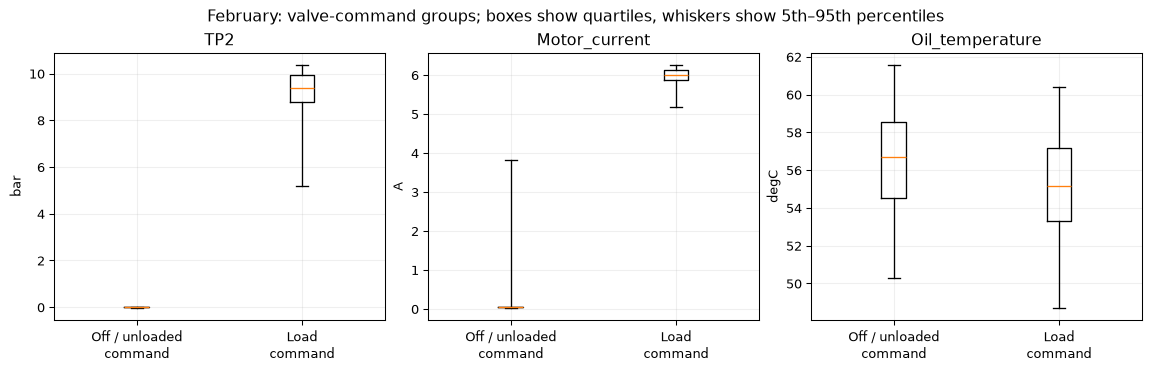

All observations are included in calculations. Full ranges remain in the earlier tables.


**Finding:** 2 reference observations have unresolved commands. Median current under a load command is 6.005 A, versus 0.038 A in the combined off/unloaded group. The latter mixes distinct physical behaviours; it is a useful initial comparison, not a complete state model. Substantial within-state ranges and transitions still need an expected-behaviour model.

In [17]:
states = ["off_or_unloaded_command", "load_command"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained")
for ax, name in zip(axes, ["TP2", "Motor_current", "Oil_temperature"]):
    samples = [state_training.loc[state_training.operating_state.eq(state), name].to_numpy() for state in states]
    ax.boxplot(samples, tick_labels=["Off / unloaded\ncommand", "Load\ncommand"], showfliers=False, whis=(5, 95))
    ax.set(title=name, ylabel=METRICS[name].unit)
fig.suptitle("February: valve-command groups; boxes show quartiles, whiskers show 5th–95th percentiles")
plt.show()
print("All observations are included in calculations. Full ranges remain in the earlier tables.")
display(Markdown(
    f"**Finding:** {int(state_counts.loc['unresolved', 'observations']) if 'unresolved' in state_counts.index else 0:,} reference observations have unresolved commands. "
    f"Median current under a load command is {current_summary.loc['load_command', 'median']:.3f} A, "
    f"versus {current_summary.loc['off_or_unloaded_command', 'median']:.3f} A in the combined off/unloaded group. "
    "The latter mixes distinct physical behaviours; it is a useful initial comparison, not a complete state model. "
    "Substantial within-state ranges and transitions still need an expected-behaviour model."
))

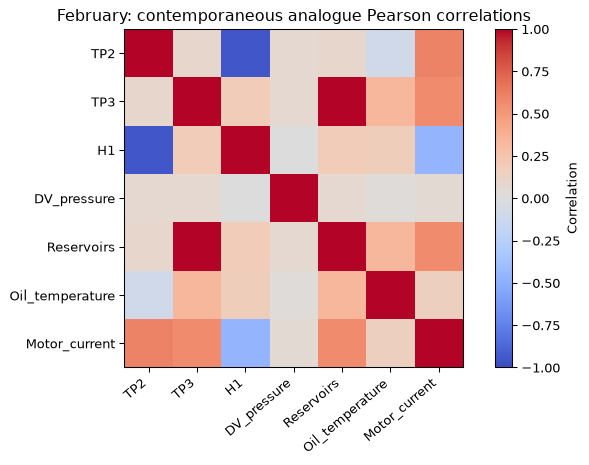

,state,first,second,pairs,pearson,spearman
0,all,TP3,Reservoirs,214850,0.99999,0.99999
1,all,TP2,Motor_current,214850,0.60495,0.10346
2,all,H1,Motor_current,214850,-0.45787,0.30571
3,load_command,TP3,Reservoirs,13031,0.99999,0.99998
4,load_command,TP2,Motor_current,13031,0.86719,0.90419
5,load_command,H1,Motor_current,13031,-0.15395,0.60232
6,off_or_unloaded_command,TP3,Reservoirs,201817,0.99999,0.99999
7,off_or_unloaded_command,TP2,Motor_current,201817,0.06874,-0.09498
8,off_or_unloaded_command,H1,Motor_current,201817,0.68123,0.58366
9,unresolved,TP3,Reservoirs,2,NaN,NaN


Pair counts are not independent sample sizes. State mixtures and shared time trends can drive correlation; correlation does not establish causation.


In [18]:
correlations = training[analog].corr()
fig, ax = plt.subplots(figsize=(7.5, 5))
plot = ax.imshow(correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(analog)), analog, rotation=40, ha="right")
ax.set_yticks(range(len(analog)), analog)
ax.grid(False)
ax.set_title("February: contemporaneous analogue Pearson correlations")
fig.colorbar(plot, ax=ax, label="Correlation")
fig.tight_layout()
plt.show()

pairs = [("TP3", "Reservoirs"), ("TP2", "Motor_current"), ("H1", "Motor_current")]
relationships = pd.concat([
    relationship_report(training, pairs),
    relationship_report(state_training, pairs, state="operating_state"),
], ignore_index=True)
display(relationships.round(5))
relationships.to_csv(OUTPUT / "relationships.csv", index=False)
print("Pair counts are not independent sample sizes. State mixtures and shared time trends can drive correlation; correlation does not establish causation.")

,TP3 minus Reservoirs (bar)
0.00,-0.012
0.01,-0.008
0.50,-0.002
0.99,0.004
1.00,0.014


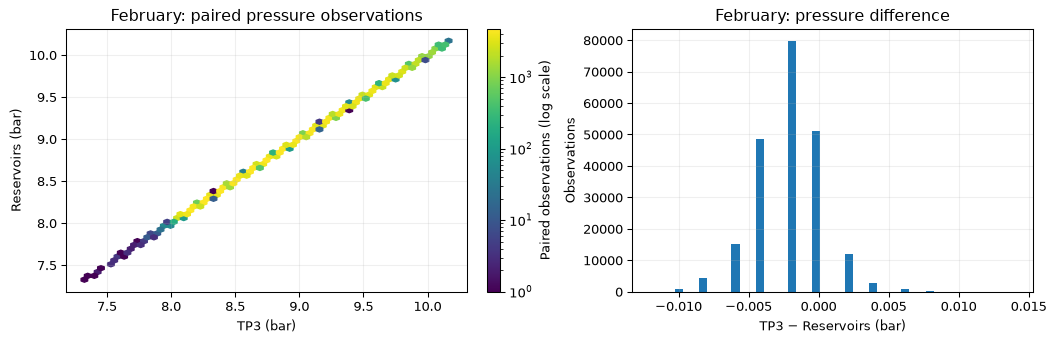

COMP / MPG equality: reference 100.000%; development 99.220%
LPS active readings in reference: 1; in development: 1,681


**Finding:** TP3/Reservoirs correlation is 0.999991; their median difference is -0.0020 bar. A relationship residual is worth testing in Notebook 02; this close agreement does not establish independent sensors or justify assuming exact equality. LPS is an existing pressure indicator, not an independent failure label. COMP/MPG agreement changes across development; they should not be assumed permanently interchangeable.

In [19]:
pressure_difference = training.TP3 - training.Reservoirs
pressure_summary = pressure_difference.quantile([0, .01, .5, .99, 1]).rename("TP3 minus Reservoirs (bar)")
display(pressure_summary.to_frame().round(5))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
density = axes[0].hexbin(training.TP3, training.Reservoirs, gridsize=55, mincnt=1, bins="log")
fig.colorbar(density, ax=axes[0], label="Paired observations (log scale)")
axes[0].set(title="February: paired pressure observations", xlabel="TP3 (bar)", ylabel="Reservoirs (bar)")
axes[1].hist(pressure_difference, bins=45)
axes[1].set(title="February: pressure difference", xlabel="TP3 − Reservoirs (bar)", ylabel="Observations")
plt.show()
print(f"COMP / MPG equality: reference {training.COMP.eq(training.MPG).mean():.3%}; development {validation.COMP.eq(validation.MPG).mean():.3%}")
print(f"LPS active readings in reference: {int(training.LPS.eq(1).sum()):,}; in development: {int(validation.LPS.eq(1).sum()):,}")
display(Markdown(
    f"**Finding:** TP3/Reservoirs correlation is {correlations.loc['TP3', 'Reservoirs']:.6f}; "
    f"their median difference is {pressure_difference.median():.4f} bar. "
    "A relationship residual is worth testing in Notebook 02; this close agreement does not establish independent sensors or justify assuming exact equality. "
    "LPS is an existing pressure indicator, not an independent failure label. COMP/MPG agreement changes across development; they should not be assumed permanently interchangeable."
))

## 6. Incident records and an evidence-based handover

Incident reports stay in a separate table. Reported start/end times are proxies, not verified leak onset, recovery or precursor onset. We preserve the inconsistent April maintenance note for the May incident. Only development incident details are displayed. No anomaly labels enter the measurement table.

In [20]:
incidents = incident_records()
development_incidents = incidents.loc[incidents.end.lt(pd.Timestamp(config["test_start"]))].copy()
display(development_incidents[["incident_id", "start", "end", "maintenance_text", "source_issue"]])
print("Reserved incident records:", int(incidents.start.ge(pd.Timestamp(config["test_start"])).sum()))
incident_coverage = []
for event in development_incidents.itertuples():
    observed = data.loc[data.timestamp.ge(event.start) & data.timestamp.le(event.end), "timestamp"]
    # Audit only complete bins inside the report: do not invent an extra final minute.
    bins = bin_coverage(observed, event.start.ceil("1min"), event.end.floor("1min"))
    incident_coverage.append({"incident_id": event.incident_id, "observations": len(observed),
                              "occupied_minutes": int(bins.occupied.sum()), "complete_report_minutes": len(bins),
                              "minute_occupancy": bins.occupied.mean()})
incident_coverage = pd.DataFrame(incident_coverage)
display(incident_coverage.round(4))
development_incidents.to_csv(OUTPUT / "development_incidents.csv", index=False)
incident_coverage.to_csv(OUTPUT / "development_incident_coverage.csv", index=False)
print("Coverage uses complete minute bins inside the report interval; the final endpoint minute is excluded because its duration is uncertain.")

,incident_id,start,end,maintenance_text,source_issue
0,report_1,2020-04-18 00:00:00,2020-04-18 23:59:00,,
1,report_2,2020-05-29 23:30:00,2020-05-30 06:00:00,Maintenance on 30Apr at 12:00,Maintenance precedes reported incident; duplicate source report number #1.


Reserved incident records: 2


,incident_id,observations,occupied_minutes,complete_report_minutes,minute_occupancy
0,report_1,8657,1435,1439,0.9972
1,report_2,2360,390,390,1.0000


Coverage uses complete minute bins inside the report interval; the final endpoint minute is excluded because its duration is uncertain.


In [21]:
handover_rows = []
for name, definition in METRICS.items():
    profile = training_profile.loc[name]
    if definition.role == "unresolved":
        decision = "Retain for assessment; resolve semantics before numerical modelling"
    elif definition.role == "existing_alarm":
        decision = "Separate existing-alarm baseline; exclude from the primary independent sensor model"
    elif definition.kind == "state":
        decision = "Candidate context; assess transitions and durations separately"
    else:
        decision = "Candidate monitored signal; compare global and command-conditioned references"
    evidence = f"{int(profile['unique'])} reference values; {int(validation_profile.loc[name, 'unique'])} development values"
    if name in analog:
        evidence += f"; lag-one minute ACF {segments.set_index('measurement').loc[name, 'acf_1minute']:.3f}"
    handover_rows.append({"measurement": name, "role": definition.role, "observed_evidence": evidence, "next_step": decision})
handover = pd.DataFrame(handover_rows)
display(handover)
handover.to_csv(OUTPUT / "notebook02_handover.csv", index=False)

manifest = {
    "dataset": config["dataset"], "doi": config["doi"], "source_hashes": config["source"]["files"],
    "boundaries": periods.to_dict(orient="records"), "timezone": config["timezone"],
    "versions": {name: version(name) for name in ["numpy", "pandas", "matplotlib", "statsmodels", "nbclient"]},
    "analysis_max_timestamp": str(data.timestamp.max()),
    "full_recording_checks": "timestamps, source index and missing-cell counts only",
    "configuration": config,
}
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
assert pd.Timestamp(manifest["analysis_max_timestamp"]) < pd.Timestamp(config["test_start"])
display(pd.Series(manifest["versions"], name="executed_version").to_frame())
print("Final-test value boundary verified. Assessment tables and manifest saved under outputs/metropt_assessment/.")

,measurement,role,observed_evidence,next_step
0,TP2,measurement,2357 reference values; 4885 development values; lag-one minute ACF 0.499,Candidate monitored signal; compare global and command-conditioned references
1,TP3,measurement,1182 reference values; 2850 development values; lag-one minute ACF 0.898,Candidate monitored signal; compare global and command-conditioned references
2,H1,measurement,1275 reference values; 1993 development values; lag-one minute ACF 0.534,Candidate monitored signal; compare global and command-conditioned references
3,DV_pressure,measurement,242 reference values; 1755 development values; lag-one minute ACF 0.005,Candidate monitored signal; compare global and command-conditioned references
4,Reservoirs,measurement,1180 reference values; 2853 development values; lag-one minute ACF 0.898,Candidate monitored signal; compare global and command-conditioned references
5,Oil_temperature,measurement,1130 reference values; 2188 development values; lag-one minute ACF 0.979,Candidate monitored signal; compare global and command-conditioned references
6,Motor_current,measurement,1083 reference values; 1494 development values; lag-one minute ACF 0.835,Candidate monitored signal; compare global and command-conditioned references
7,COMP,context,2 reference values; 2 development values,Candidate context; assess transitions and durations separately
8,DV_eletric,context,2 reference values; 2 development values,Candidate context; assess transitions and durations separately
9,Towers,context,2 reference values; 2 development values,Candidate context; assess transitions and durations separately


,executed_version
numpy,2.3.5
pandas,2.3.3
matplotlib,3.11.2
statsmodels,0.14.6
nbclient,0.11.0


Final-test value boundary verified. Assessment tables and manifest saved under outputs/metropt_assessment/.


### Recommendation for Notebook 02

Start by comparing simple individual-signal references with **valve-command-conditioned expected behaviour**, using February for fitting and March–May for development. Retain separate checks for command duration and transitions. Investigate the TP3–Reservoirs relationship as a candidate residual, without assuming physical independence. Keep the existing LPS alarm as a separate comparison.

Use the observed temporal dependence to assess residuals before setting alert thresholds. Decide an operational aggregation and gap policy explicitly; the minute means here are diagnostic and are not a finished feature pipeline. A state definition that pools off and unloaded operation may need refinement, but that requires an independently justified rule and a fair comparison.

**Limits and unresolved decisions:** one asset and four reported incidents cannot establish cross-company performance. Coverage gaps limit event observability. Pulse encoding, oil-level polarity, timestamp timezone, sensor calibration and the inconsistent maintenance note remain unresolved. There is no verified normal/anomalous label for every row, no failure probability estimate and no established daily/weekly seasonal model. Final test sensor values remain uninspected.

**Reusable deliverable:** a documented assessment process and generic calculations. A different dataset supplies its own reader, measurement metadata, operating context and incident interpretation. No plugin architecture or universal model selector is needed.